# Mobile Game Player Spending Segmentation
## 02 — Data cleaning and quality review

### Project objective
NovaPlay Studios operates a free-to-play mobile game and uses in-app purchases as a key revenue stream. The business objective is to increase IAP revenue by **15% within three months of deploying the predictive ML model** through more relevant player offers. This project prepares demographic and early-gameplay data for a supervised model that predicts a new player's likely spending segment within the first **30-day period**: **Minnow** (low or no spending), **Dolphin** (moderate spending), or **Whale** (high spending), so the marketing team can tailor offers before month-end.

### Purpose of this notebook
Prepare and quality-check the player dataset before modeling.The cleaned output is **`02_clean_data.csv`**. `UserID` is retained for record checks, not as a model feature. `InAppPurchaseAmount` is retained for data-quality review, not as a predictor of a segment defined by spending.

This notebook follows a repeatable data-cleaning workflow:

1. Load and inspect the generated CSV.
2. Measure missing values and duplicates before changing anything.
3. Standardize data types so numeric and date values can be analyzed.
4. Visualize IQR outlier candidates and apply documented business rules.
5. Standardize labels, handle missing values, remove exact duplicates, and validate the result.

**Important:** An IQR rule identifies unusual values; it does not prove that a value is wrong. Decisions below use both plots and plausible domain bounds. The notebook preserves the raw dataframe as `df_raw` so changes can be audited.


## 1. Load the generated dataset

Upload `mobile_game_players_expanded_dirty.csv` created by the generation notebook. The uploaded file is read as text/numbers as stored; we will convert mixed-format columns in a later step.

In [2]:
from google.colab import files
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()
input_file = next(iter(uploaded))

df_raw = pd.read_csv(input_file)
df = df_raw.copy()

print('Loaded file:', input_file)
print('Rows and columns:', df.shape)
display(df.head())


Saving mobile_game_players_expanded_dirty.csv to mobile_game_players_expanded_dirty (1).csv
Loaded file: mobile_game_players_expanded_dirty (1).csv
Rows and columns: (250000, 23)


,UserID,Age,Gender,Country,Device,GameGenre,SessionCount,AverageSessionLength,SpendingSegment,InAppPurchaseAmount,...,AcquisitionChannel,InstallDate,ActiveDays30d,PlayerLevel30d,AdsWatched30d,SocialActions30d,GuildMember,PushNotificationsOptIn,PurchaseCount30d,WinRate
0,PLAYER005364744676376,49.0,Male,Norway,android,Battle Royale,9.0,12.83,Minnow,11.4,...,Organic,2035-01-01,5.0,16,4,3,No,Yes,1,0.214
1,PLAYER447523025485744,15.0,Male,Switzerland,iOS,Action RPG,11.0,19.39,Minnow,6.37,...,Cross-promotion,2023-12-19 00:00:00,4.0,14,5,5,No,No,1,0.152
2,PLAYER445146626174337,23.0,Male,China,Android,Fighting,9.0,8.87,Minnow,15.81,...,Cross-promotion,06/04/2024,9.0,12,6,3,Yes,Yes,1,0.499
3,PLAYER673007615056419,31.0,Male,Mexico,Android,Racing,12.0,19.56,Minnow,13.49,...,Referral,2024-04-26 00:00:00,8.0,7,5,1,No,No,0,0.409
4,PLAYER316428408427736,37.0,Female,India,Android,Battle Royale,NaN,15.23,Minnow,10.86,...,Referral,2023-10-03 00:00:00,4.0,19,2,2,Yes,Yes,2,0.346


## 2. Initial inspection — understand before editing

Check column names, data types, missing values, exact duplicates, and basic numeric summaries. This is the baseline for comparing before and after cleaning.

In [3]:
print('Dataset shape:', df.shape)
print('Columns:', df.columns.tolist())
print('Exact duplicate rows:', int(df.duplicated().sum()))

print('Column types and non-missing counts:')
df.info()

missing_before = df.isna().sum().sort_values(ascending=False)
display(missing_before.to_frame('missing_rows'))

print('Numeric summary (raw types that pandas already recognizes):')
display(df.describe())


Dataset shape: (250000, 23)
Columns: ['UserID', 'Age', 'Gender', 'Country', 'Device', 'GameGenre', 'SessionCount', 'AverageSessionLength', 'SpendingSegment', 'InAppPurchaseAmount', 'FirstPurchaseDaysAfterInstall', 'PaymentMethod', 'LastPurchaseDate', 'AcquisitionChannel', 'InstallDate', 'ActiveDays30d', 'PlayerLevel30d', 'AdsWatched30d', 'SocialActions30d', 'GuildMember', 'PushNotificationsOptIn', 'PurchaseCount30d', 'WinRate']
Exact duplicate rows: 2500
Column types and non-missing counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   UserID                         250000 non-null  object 
 1   Age                            239011 non-null  float64
 2   Gender                         240621 non-null  object 
 3   Country                        236427 non-null  object 
 4   Device                

,missing_rows
FirstPurchaseDaysAfterInstall,39897
PaymentMethod,22007
LastPurchaseDate,18437
InAppPurchaseAmount,17071
Country,13573
AcquisitionChannel,12490
Age,10989
AverageSessionLength,9909
Gender,9379
Device,4992


Numeric summary (raw types that pandas already recognizes):


,Age,SessionCount,FirstPurchaseDaysAfterInstall,ActiveDays30d,PlayerLevel30d,AdsWatched30d,SocialActions30d,PurchaseCount30d,WinRate
count,239011.000000,245018.000000,210103.000000,246237.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000
mean,33.441327,10.341020,15.386415,6.759468,12.985692,5.204572,4.187188,1.484496,0.401517
std,12.415462,4.407895,8.952134,3.765634,7.175833,2.402571,2.160181,1.362612,0.157683
min,-9.000000,-29.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,23.000000,7.000000,8.000000,4.000000,8.000000,3.000000,3.000000,0.000000,0.289000
50%,33.000000,10.000000,16.000000,6.000000,12.000000,5.000000,4.000000,1.000000,0.394000
75%,44.000000,13.000000,23.000000,9.000000,17.000000,7.000000,5.000000,2.000000,0.506000
max,66.000000,44.000000,30.000000,30.000000,80.000000,22.000000,19.000000,15.000000,1.998236


## 3. Missing-value audit — measure and visualize

The bar chart shows which original columns have the most missing values. At this point, do not fill them yet: some values may become missing during numeric/date conversion, and the cleaning decision depends on the column's meaning.

,missing_rows,missing_percent
FirstPurchaseDaysAfterInstall,39897,15.96
PaymentMethod,22007,8.80
LastPurchaseDate,18437,7.37
InAppPurchaseAmount,17071,6.83
Country,13573,5.43
AcquisitionChannel,12490,5.00
Age,10989,4.40
AverageSessionLength,9909,3.96
Gender,9379,3.75
Device,4992,2.00


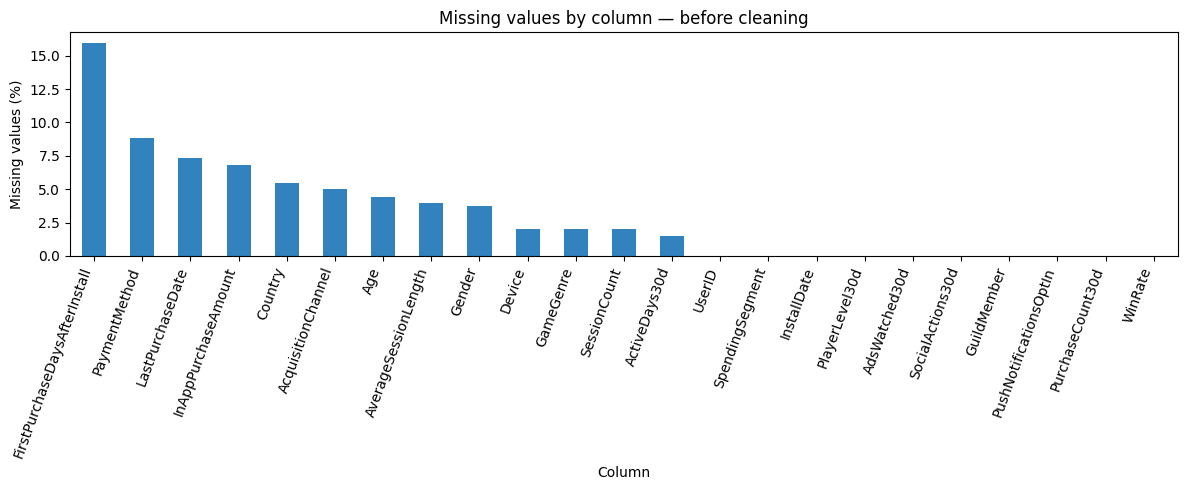

In [4]:
missing_summary = pd.DataFrame({
    'missing_rows': df.isna().sum(),
    'missing_percent': (df.isna().mean() * 100).round(2),
})
missing_summary = missing_summary.sort_values('missing_percent', ascending=False)
display(missing_summary)

plt.figure(figsize=(12, 5))
missing_summary['missing_percent'].plot.bar(color='#3182bd')
plt.title('Missing values by column — before cleaning')
plt.xlabel('Column')
plt.ylabel('Missing values (%)')
plt.xticks(rotation=70, ha='right')
plt.tight_layout()
plt.show()


### Missing-value decision — why we will not fill every column the same way

- **Target (`SpendingSegment`):** a supervised model cannot learn a missing target label. Standardize the labels; remove rows only if the target is still missing. Never invent a target.
- **Numeric predictors:** convert malformed values to missing, then use the median. The median is less affected by extreme values than the mean.
- **Categorical predictors:** use an explicit `Unknown` / `Not recorded` category rather than guessing a player's answer.
- **Dates:** do not invent a date just to make the file look complete. Keep missing dates as `NaT` and report them; if a later model needs dates, handle them in a time-aware feature pipeline.

These are transparent project decisions, not universal rules. Review them with the project requirements before final submission.

## 4. Standardize formats so values can be analyzed

The generator intentionally mixed numeric values with text such as `600 sec` or `$12.50`, and wrote dates in different formats. This step parses them into consistent units/types. Invalid text becomes missing (`NaN`/`NaT`) so it can be counted and handled explicitly.

In [5]:
# Convert session duration to minutes. Values like '600 sec' become 10 minutes.
duration_text = df['AverageSessionLength'].astype('string').str.strip()
seconds_text = duration_text.str.extract(r'^([0-9.]+)\s*sec$', expand=False)
duration_number = pd.to_numeric(duration_text, errors='coerce')
seconds_mask = seconds_text.notna()
duration_number.loc[seconds_mask] = (
    pd.to_numeric(seconds_text[seconds_mask], errors='coerce') / 60
)
df['AverageSessionLength'] = duration_number

# Remove currency symbols and commas before converting purchase amount to numbers.
amount_text = df['InAppPurchaseAmount'].astype('string').str.replace('$', '', regex=False)
amount_text = amount_text.str.replace(',', '', regex=False).str.strip()
df['InAppPurchaseAmount'] = pd.to_numeric(amount_text, errors='coerce')

# Convert numeric fields. Non-numeric strings become NaN.
numeric_columns = [
    'Age', 'SessionCount', 'FirstPurchaseDaysAfterInstall', 'ActiveDays30d',
    'PlayerLevel30d', 'AdsWatched30d', 'SocialActions30d', 'PurchaseCount30d', 'WinRate'
]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors='coerce')

# Parse the known date formats used by the generator: ISO, month/day/year, day-month-year.
def parse_mixed_date(series):
    text = series.astype('string').str.strip()
    result = pd.Series(pd.NaT, index=series.index, dtype='datetime64[ns]')

    iso_mask = text.str.match(r'^\d{4}-\d{2}-\d{2}$', na=False)
    slash_mask = text.str.match(r'^\d{1,2}/\d{1,2}/\d{4}$', na=False)
    day_first_mask = text.str.match(r'^\d{1,2}-\d{1,2}-\d{4}$', na=False)

    result.loc[iso_mask] = pd.to_datetime(text.loc[iso_mask], format='%Y-%m-%d', errors='coerce')
    result.loc[slash_mask] = pd.to_datetime(text.loc[slash_mask], format='%m/%d/%Y', errors='coerce')
    result.loc[day_first_mask] = pd.to_datetime(text.loc[day_first_mask], format='%d-%m-%Y', errors='coerce')
    return result

df['InstallDate'] = parse_mixed_date(df['InstallDate'])
df['LastPurchaseDate'] = parse_mixed_date(df['LastPurchaseDate'])

print('Parsed numeric and date columns. Newly invalid values are now counted as missing.')
print('AverageSessionLength unit: minutes')
print('Date column types:', df[['InstallDate', 'LastPurchaseDate']].dtypes.to_dict())


Parsed numeric and date columns. Newly invalid values are now counted as missing.
AverageSessionLength unit: minutes
Date column types: {'InstallDate': dtype('<M8[ns]'), 'LastPurchaseDate': dtype('<M8[ns]')}


## 5. Outlier analysis — IQR table and boxplots

The IQR fences (Q1 − 1.5×IQR and Q3 + 1.5×IQR) flag statistical candidates. The plots help locate them. We will not automatically delete every IQR candidate: unusual but possible players should remain in the data.

,Q1,Q3,IQR,lower_fence,upper_fence,IQR_candidate_count
column,,,,,,
Age,23.00,44.00,21.00,-8.50,75.50,82
SessionCount,7.00,13.00,6.00,-2.00,22.00,3408
AverageSessionLength,12.45,27.37,14.92,-9.93,49.75,696
ActiveDays30d,4.00,9.00,5.00,-3.50,16.50,4291
PlayerLevel30d,8.00,17.00,9.00,-5.50,30.50,6202
PurchaseCount30d,0.00,2.00,2.00,-3.00,5.00,2849


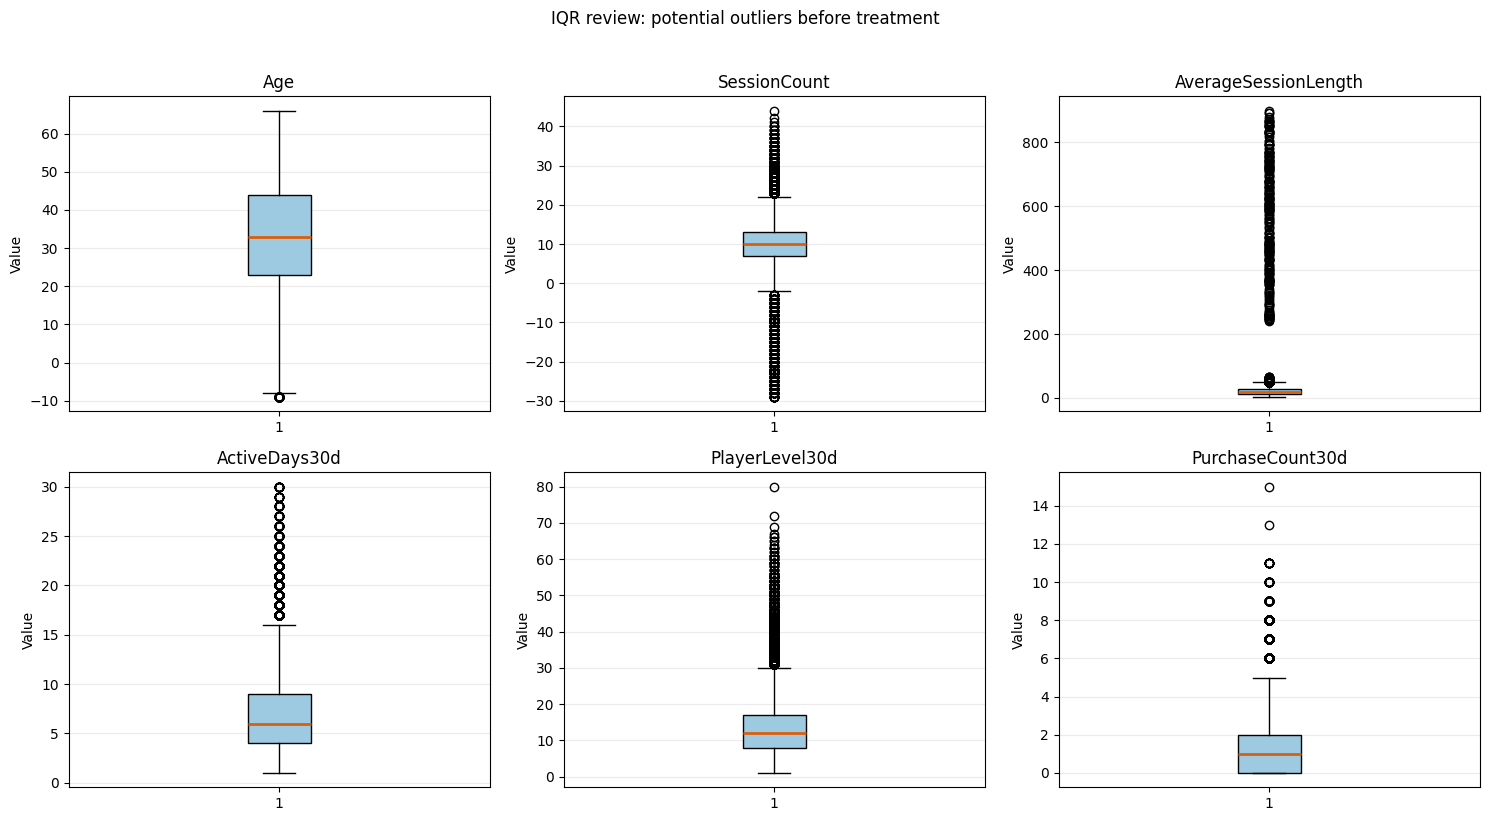

In [6]:
outlier_columns = [
    'Age', 'SessionCount', 'AverageSessionLength', 'ActiveDays30d',
    'PlayerLevel30d', 'PurchaseCount30d'
]

outlier_rows = []
for column in outlier_columns:
    values = df[column].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    mask = (df[column] < lower_fence) | (df[column] > upper_fence)
    outlier_rows.append({
        'column': column, 'Q1': q1, 'Q3': q3, 'IQR': iqr,
        'lower_fence': lower_fence, 'upper_fence': upper_fence,
        'IQR_candidate_count': int(mask.sum()),
    })

outlier_summary = pd.DataFrame(outlier_rows).set_index('column')
display(outlier_summary.round(2))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column in zip(axes.flat, outlier_columns):
    ax.boxplot(df[column].dropna(), vert=True, patch_artist=True,
               boxprops={'facecolor': '#9ecae1'},
               medianprops={'color': '#d95f0e', 'linewidth': 2})
    ax.set_title(column)
    ax.set_ylabel('Value')
    ax.grid(axis='y', alpha=.25)
plt.suptitle('IQR review: potential outliers before treatment', y=1.02)
plt.tight_layout()
plt.show()


### Outlier decision — combine statistical flags with domain logic

**Decision for this dataset:**

- Do not remove a row solely because IQR marked it. IQR depends on the distribution and can flag valid heavy players.
- Treat clearly impossible values as invalid: negative age, negative session count, negative activity counts, and win rate outside 0–1 become missing.
- Treat an average session length above 240 minutes (four hours) as implausible for an *average individual session* in this project and mark it missing rather than deleting the player. This is an explicit project threshold; change it if you have a source-backed business definition.
- Keep other IQR candidates for now. Review them with subject knowledge before capping or removing them.

Marking a bad measurement as missing preserves the player's other useful information and makes the decision auditable.

In [7]:
# Apply only the explicit validity rules described above.
invalid_counts = {}

invalid_age = (df['Age'] < 0) | (df['Age'] > 100)
invalid_counts['Age outside 0-100'] = int(invalid_age.sum())
df.loc[invalid_age, 'Age'] = np.nan

invalid_sessions = df['SessionCount'] < 0
invalid_counts['Negative SessionCount'] = int(invalid_sessions.sum())
df.loc[invalid_sessions, 'SessionCount'] = np.nan

nonnegative_columns = ['FirstPurchaseDaysAfterInstall', 'ActiveDays30d', 'PlayerLevel30d', 'AdsWatched30d', 'SocialActions30d', 'PurchaseCount30d']
for column in nonnegative_columns:
    invalid = df[column] < 0
    invalid_counts[f'Negative {column}'] = int(invalid.sum())
    df.loc[invalid, column] = np.nan

invalid_active_days = df['ActiveDays30d'] > 30
invalid_counts['ActiveDays30d above 30'] = int(invalid_active_days.sum())
df.loc[invalid_active_days, 'ActiveDays30d'] = np.nan

invalid_duration = (df['AverageSessionLength'] <= 0) | (df['AverageSessionLength'] > 240)
invalid_counts['AverageSessionLength <= 0 or > 240 min'] = int(invalid_duration.sum())
df.loc[invalid_duration, 'AverageSessionLength'] = np.nan

invalid_win_rate = (df['WinRate'] < 0) | (df['WinRate'] > 1)
invalid_counts['WinRate outside 0-1'] = int(invalid_win_rate.sum())
df.loc[invalid_win_rate, 'WinRate'] = np.nan

display(pd.Series(invalid_counts, name='values_marked_missing').to_frame())


,values_marked_missing
Age outside 0-100,752
Negative SessionCount,503
Negative FirstPurchaseDaysAfterInstall,0
Negative ActiveDays30d,0
Negative PlayerLevel30d,0
Negative AdsWatched30d,0
Negative SocialActions30d,0
Negative PurchaseCount30d,0
ActiveDays30d above 30,0
AverageSessionLength <= 0 or > 240 min,251


## 6. Check date logic

A future install date is impossible for this dataset's timeline. We flag it as missing rather than replacing it with a guessed date. We also check whether install dates occur after last-purchase dates; investigate these records before deciding whether to correct or mark them missing.

In [8]:
reference_date = pd.Timestamp('2026-11-20')
future_install = df['InstallDate'] > reference_date
install_after_purchase = df['InstallDate'].notna() & df['LastPurchaseDate'].notna() & (df['InstallDate'] > df['LastPurchaseDate'])

print('Install dates after reference date:', int(future_install.sum()))
print('Install dates later than last-purchase dates:', int(install_after_purchase.sum()))

# The synthetic generator deliberately inserts one future date. Mark it missing.
df.loc[future_install, 'InstallDate'] = pd.NaT

# A last purchase before install is chronologically inconsistent; preserve the row but mark the bad date missing.
df.loc[install_after_purchase, 'LastPurchaseDate'] = pd.NaT


Install dates after reference date: 1
Install dates later than last-purchase dates: 1


## 7. Standardize category labels

Trim extra spaces and normalize spelling/capitalization. Map known aliases to one canonical label. Keep unexpected values visible rather than silently forcing them into a category.

In [9]:
# Normalize simple labels by trimming spaces and using consistent capitalization.
category_columns = [
    'Gender', 'Country', 'Device', 'GameGenre', 'SpendingSegment',
    'PaymentMethod', 'AcquisitionChannel', 'GuildMember', 'PushNotificationsOptIn'
]
for column in category_columns:
    df[column] = df[column].astype('string').str.strip()

# Normalize the target labels explicitly.
df['SpendingSegment'] = df['SpendingSegment'].str.lower().map({
    'minnow': 'Minnow', 'dolphin': 'Dolphin', 'whale': 'Whale'
})

# Normalize gender and common country aliases (including the intentionally inconsistent forms).
gender_values = df['Gender'].str.lower().map({
    'male': 'Male', 'female': 'Female', 'other': 'Other', 'non-binary': 'Non-binary'
})
df['Gender'] = gender_values.fillna(df['Gender'].str.title())

country_text = df['Country'].str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
country_aliases = {
    'usa': 'United States', 'us': 'United States', 'united states': 'United States',
    'uk': 'United Kingdom', 'united kingdom': 'United Kingdom',
    'uae': 'United Arab Emirates', 'united arab emirates': 'United Arab Emirates'
}
df['Country'] = country_text.map(country_aliases).fillna(country_text.str.title())

# Normalize device names and common payment-method variations.
df['Device'] = df['Device'].str.lower().map({'android': 'Android', 'ios': 'iOS'}).fillna(df['Device'])
df['PaymentMethod'] = df['PaymentMethod'].str.lower().str.replace(' ', '', regex=False).map({
    'paypal': 'PayPal', 'creditcard': 'Credit Card', 'debitcard': 'Debit Card',
    'applepay': 'Apple Pay', 'googlepay': 'Google Pay'
}).fillna(df['PaymentMethod'])

# Normalize known genre variations.
df['GameGenre'] = df['GameGenre'].str.lower().map({
    'battleroyale': 'Battle Royale', 'battle royale': 'Battle Royale',
    'action rpg': 'Action RPG'
}).fillna(df['GameGenre'])

print('Spending segment values after standardization:')
print(df['SpendingSegment'].value_counts(dropna=False))
print('Device values after standardization:')
print(df['Device'].value_counts(dropna=False).head(10))


Spending segment values after standardization:
SpendingSegment
Minnow     210411
Dolphin     34017
Whale        5572
Name: count, dtype: int64
Device values after standardization:
Device
Android    143495
iOS        101513
<NA>         4992
Name: count, dtype: int64


## 8. Duplicate records — measure, decide, remove

The generator intentionally appended exact duplicate rows. In this project, exact duplicates are not separate players or events, so remove them. If duplicates represented repeated legitimate transactions in another dataset, the decision would be different.

In [10]:
duplicate_count_before = int(df.duplicated().sum())
print('Exact duplicates before removal:', duplicate_count_before)

df = df.drop_duplicates().copy()
df = df.reset_index(drop=True)

print('Rows after duplicate removal:', len(df))
print('Exact duplicates after removal:', int(df.duplicated().sum()))


Exact duplicates before removal: 2500
Rows after duplicate removal: 247500
Exact duplicates after removal: 0


## 9. Handle remaining missing values

First review the missingness after parsing and invalid-value checks. Then apply a simple, explainable policy: median for numeric fields, `Unknown` for categorical predictors, do not invent target labels, and retain missing dates as `NaT`.

,missing_rows,missing_percent
InstallDate,217800,88.00
FirstPurchaseDaysAfterInstall,39498,15.96
PaymentMethod,21801,8.81
LastPurchaseDate,18266,7.38
InAppPurchaseAmount,16896,6.83
Country,13426,5.42
AcquisitionChannel,12375,5.00
Age,11624,4.70
AverageSessionLength,10134,4.09
Gender,9294,3.76


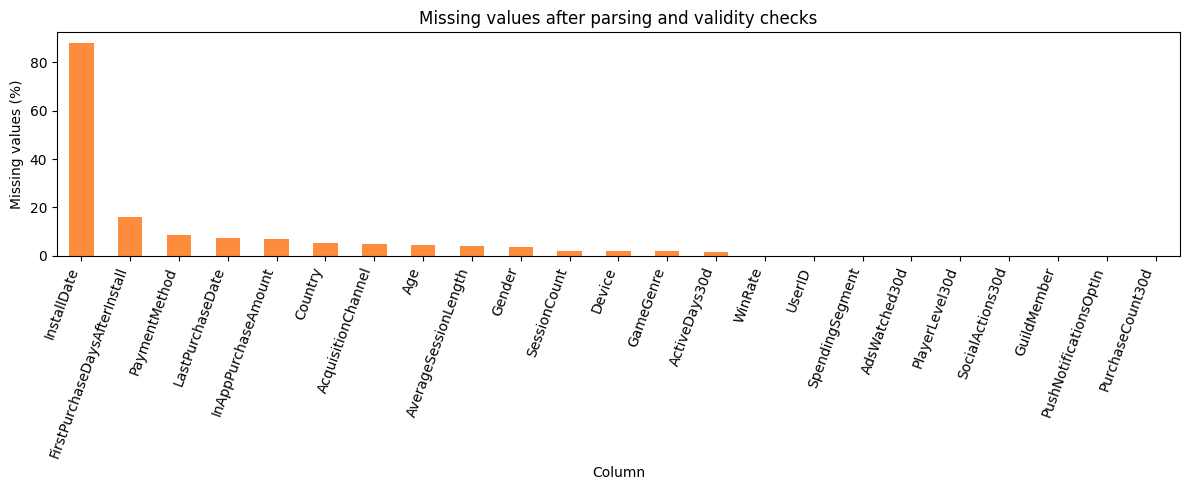

In [11]:
missing_after_validation = pd.DataFrame({
    'missing_rows': df.isna().sum(),
    'missing_percent': (df.isna().mean() * 100).round(2),
}).sort_values('missing_percent', ascending=False)
display(missing_after_validation)

plt.figure(figsize=(12, 5))
missing_after_validation['missing_percent'].plot.bar(color='#fd8d3c')
plt.title('Missing values after parsing and validity checks')
plt.xlabel('Column')
plt.ylabel('Missing values (%)')
plt.xticks(rotation=70, ha='right')
plt.tight_layout()
plt.show()


### Missing-value treatment decisions

- **Numeric columns:** replace missing values with each column's median. This is a basic coursework strategy; for a final predictive model, fit imputation only on the training split to prevent leakage.
- **Categorical predictors:** fill with `Unknown` so the missingness is explicit.
- **Target:** remove rows with a missing or unrecognized `SpendingSegment`; do not impute the answer.
- **Dates:** keep as missing (`NaT`) rather than fabricate event dates. Report their remaining counts.

`PaymentMethod` and purchase dates can be structurally absent for some players, so `Unknown`/missing is safer than assuming a specific payment behavior.

In [12]:
target_missing = df['SpendingSegment'].isna()
rows_without_target = int(target_missing.sum())
print('Rows removed because target is missing/invalid:', rows_without_target)
df = df.loc[~target_missing].copy()

# Median imputation for numeric fields. Save the medians for documentation.
numeric_columns = df.select_dtypes(include='number').columns.tolist()
numeric_medians = df[numeric_columns].median()
df[numeric_columns] = df[numeric_columns].fillna(numeric_medians)

# Fill missing category values with a visible label rather than guessing.
categorical_columns = df.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
for column in categorical_columns:
    if column != 'UserID':
        df[column] = df[column].fillna('Unknown')

print('Numeric medians used:')
display(numeric_medians.to_frame('median_used'))
print('Remaining missing values (dates are intentionally retained):')
display(df.isna().sum().to_frame('missing_rows').query('missing_rows > 0'))


Rows removed because target is missing/invalid: 0
Numeric medians used:


,median_used
Age,33.0
SessionCount,10.0
AverageSessionLength,19.92
InAppPurchaseAmount,11.91
FirstPurchaseDaysAfterInstall,16.0
ActiveDays30d,6.0
PlayerLevel30d,12.0
AdsWatched30d,5.0
SocialActions30d,4.0
PurchaseCount30d,1.0


Remaining missing values (dates are intentionally retained):


,missing_rows
LastPurchaseDate,18266
InstallDate,217800


## 10. Final validation — compare before and after

Confirm dimensions, duplicate count, target labels, numeric bounds, and remaining missing dates. A successful cleaning step should be explainable; it does not necessarily mean every missing value must be fabricated or removed.

Raw shape: (250000, 23)
Cleaned shape: (247500, 23)
Exact duplicates remaining: 0
Missing values remaining:


,missing_rows
LastPurchaseDate,18266
InstallDate,217800


Target distribution after cleaning:


,players
SpendingSegment,
Minnow,208328
Dolphin,33670
Whale,5502


Numeric bounds after cleaning:


,Age,SessionCount,AverageSessionLength,WinRate
count,247500.00,247500.00,247500.0,247500.00
mean,33.53,10.39,20.39,0.40
std,11.95,4.19,9.4,0.15
min,13.00,1.00,2.87,0.00
25%,24.00,7.00,12.77,0.29
50%,33.00,10.00,19.92,0.39
75%,43.00,13.00,27.01,0.50
max,66.00,44.00,65.76,1.00


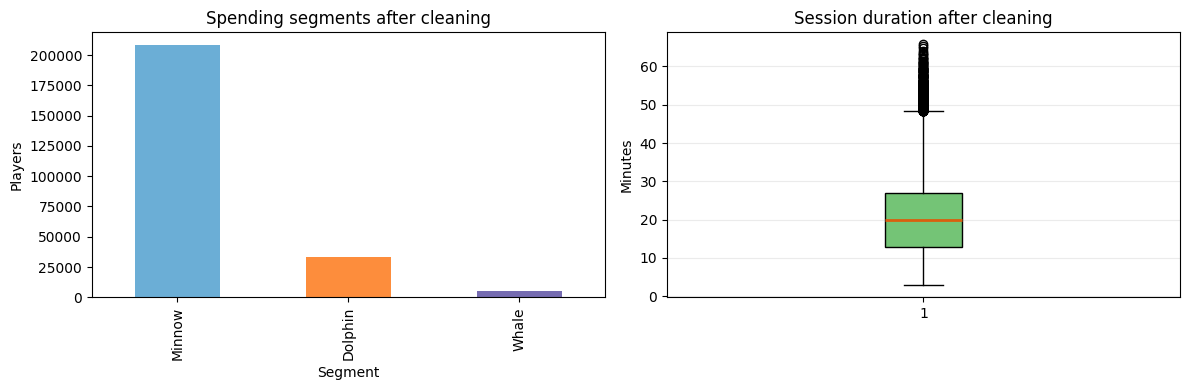

In [13]:
print('Raw shape:', df_raw.shape)
print('Cleaned shape:', df.shape)
print('Exact duplicates remaining:', int(df.duplicated().sum()))
print('Missing values remaining:')
display(df.isna().sum().to_frame('missing_rows').query('missing_rows > 0'))

print('Target distribution after cleaning:')
display(df['SpendingSegment'].value_counts().to_frame('players'))

print('Numeric bounds after cleaning:')
display(df[['Age', 'SessionCount', 'AverageSessionLength', 'WinRate']].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['SpendingSegment'].value_counts().reindex(['Minnow', 'Dolphin', 'Whale']).plot.bar(
    ax=axes[0], color=['#6baed6', '#fd8d3c', '#756bb1']
)
axes[0].set_title('Spending segments after cleaning')
axes[0].set_xlabel('Segment')
axes[0].set_ylabel('Players')

axes[1].boxplot(df['AverageSessionLength'], patch_artist=True,
                boxprops={'facecolor': '#74c476'},
                medianprops={'color': '#d95f0e', 'linewidth': 2})
axes[1].set_title('Session duration after cleaning')
axes[1].set_ylabel('Minutes')
axes[1].grid(axis='y', alpha=.25)
plt.tight_layout()
plt.show()


## 11. Export the cleaned dataset

Save a new file so the original dirty dataset remains unchanged. Download the cleaned CSV from Colab.

In [14]:
OUTPUT_FILE = 'mobile_game_players_cleaned.csv'
df.to_csv(OUTPUT_FILE, index=False)
print('Saved:', OUTPUT_FILE)

from google.colab import files
files.download(OUTPUT_FILE)


Saved: mobile_game_players_cleaned.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Cleaning decisions summary

| Issue | Evidence/check | Action | Reason |
|---|---|---|---|
| Missing values | Counts and percentage chart | Numeric median; categorical `Unknown`; target missing rows removed; missing dates retained | Avoid inventing labels or dates; use a simple robust baseline for numeric fields |
| Outliers | IQR fences and boxplots | Keep statistical candidates unless a business rule says invalid | IQR flags unusual values, not automatically errors |
| Impossible values | Domain checks | Mark negative counts, invalid win rates, and implausible durations as missing | These violate the variable's meaning |
| Mixed formats | Parsing checks | Convert currency/durations/dates to standard representations | Enable valid comparisons and analysis |
| Inconsistent categories | Value counts and aliases | Trim/canonicalize known variants | Avoid duplicate categories caused by spelling/case |
| Exact duplicates | `duplicated()` count | Drop exact duplicate rows | They were deliberately appended and do not represent extra players |

**Modeling note:** for predictive evaluation, perform train/test splitting before fitting imputers or other learned transformations. Avoid using `InAppPurchaseAmount` if it directly reveals the `SpendingSegment` target.
